In [1]:
lugares = {
    "UNSAAC": (-13.521763, -71.958256),
    "Mi casa": (-13.539188, -71.911134),
    "Casa de mis padres": (-12.868190, -72.693778),
    "Sacsayhuaman": (-13.509601, -71.982229),
    "Plaza de Armas": (-13.516653, -71.979182),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

UNSAAC: lat=-13.521763, lon=-71.958256
Mi casa: lat=-13.539188, lon=-71.911134
Casa de mis padres: lat=-12.86819, lon=-72.693778
Sacsayhuaman: lat=-13.509601, lon=-71.982229
Plaza de Armas: lat=-13.516653, lon=-71.979182


In [2]:
##Celda 2: sacar las listas
lats = [v[0] for v in lugares.values()]
lons = [v[1] for v in lugares.values()]
nombres = list(lugares.keys())

print(lats)
print(lons)
print(nombres)

[-13.521763, -13.539188, -12.86819, -13.509601, -13.516653]
[-71.958256, -71.911134, -72.693778, -71.982229, -71.979182]
['UNSAAC', 'Mi casa', 'Casa de mis padres', 'Sacsayhuaman', 'Plaza de Armas']


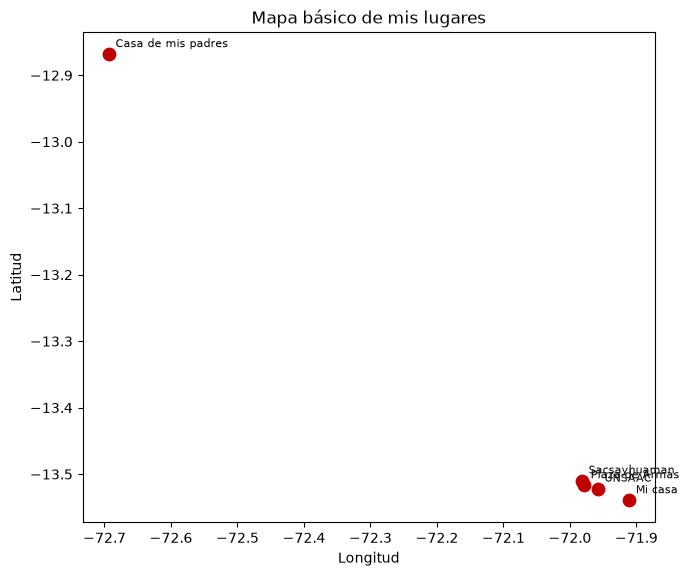

In [3]:
###Celda 3: graficar y guardar
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(lons, lats, c="#C00000", s=80)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mapa básico de mis lugares")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("mapa_basico.png")
plt.show()

In [4]:
#Celda 4: la función de Haversine
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos coordenadas (fórmula de Haversine)."""
    R = 6371.0  # radio promedio de la Tierra en km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlambda/2)**2
    c = 2*math.atan2(math.sqrt(a), math.sqrt(1-a))
    return R*c

In [7]:
###Celda 4b con los dos lugares del docente:
print(distancia_haversine(-13.5170, -71.9785, -13.5075, -71.9817))

1.1115653498374942


In [5]:
###Celda 5: distancias desde tu primer lugar
primer = list(lugares.keys())[0]
lat0, lon0 = lugares[primer]

for nombre, (lat, lon) in lugares.items():
    if nombre == primer:
        continue
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"{primer} -> {nombre}: {d:.4f} km")

UNSAAC -> Mi casa: 5.4503 km
UNSAAC -> Casa de mis padres: 107.8049 km
UNSAAC -> Sacsayhuaman: 2.9234 km
UNSAAC -> Plaza de Armas: 2.3327 km


In [6]:
###Celda 6: par más cercano y más lejano
from itertools import combinations

pares = []
for (n1, (a1, o1)), (n2, (a2, o2)) in combinations(lugares.items(), 2):
    d = distancia_haversine(a1, o1, a2, o2)
    pares.append((d, n1, n2))

pares.sort()  # ordena de menor a mayor distancia

for d, n1, n2 in pares:
    print(f"{n1} <-> {n2}: {d:.4f} km")

print()
print("Par MÁS CERCANO:", pares[0])
print("Par MÁS LEJANO:", pares[-1])

Sacsayhuaman <-> Plaza de Armas: 0.8505 km
UNSAAC <-> Plaza de Armas: 2.3327 km
UNSAAC <-> Sacsayhuaman: 2.9234 km
UNSAAC <-> Mi casa: 5.4503 km
Mi casa <-> Plaza de Armas: 7.7717 km
Mi casa <-> Sacsayhuaman: 8.3607 km
Casa de mis padres <-> Sacsayhuaman: 104.9804 km
Casa de mis padres <-> Plaza de Armas: 105.7550 km
UNSAAC <-> Casa de mis padres: 107.8049 km
Mi casa <-> Casa de mis padres: 112.8946 km

Par MÁS CERCANO: (0.850535712561639, 'Sacsayhuaman', 'Plaza de Armas')
Par MÁS LEJANO: (112.89457683812411, 'Mi casa', 'Casa de mis padres')
